# 03b — Where the queue and the built fleet are (figure F9)

This notebook puts every interconnection request in the LBNL file on a map of the contiguous United States, by county, beside the operating fleet from EIA-860M, so that the three ISOs with usable timing data (ERCOT, PJM, CAISO) can be seen in the context of the whole queue, and so a portfolio manager can see where the capacity waiting to connect sits.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet` | notebook 02 — every request, status at end-2024, county FIPS |
| in | `data/raw/eia860m/eia860m_2026-07.parquet` | notebook 01 — operable generators with coordinates |
| in | `data/raw/geo/cb_2020_us_county_20m.zip`, `cb_2020_us_state_20m.zip` | U.S. Census Bureau cartographic boundary files (public domain), SHA-256 in `data/raw/geo/SHA256.txt` |
| out | `results/map_unmatched.csv` | requests without a usable county code, by region |
| out | `results/map_counts_by_state.csv` | requests and MW by state and status |
| out | `results/map_built_share_by_state.csv` | share of resolved 2010–2018 entrants that reached operation, by state |
| out | `figures/F9_project_map.png/.svg`, `figures/03b_project_map/03b_02_built_share_by_state.png/.svg` | figure F9 and its companion |
| out | `results/map_checks.csv` | this notebook's checks, PASS/FAIL |
| out | `results/state_archetypes.csv`, `results/archetype_profiles.csv`, `figures/F25_state_archetypes.*` | state archetypes from k-means on market features, validated on 2017–2019 outcomes (section 5) |

## Setup

In [1]:
import glob
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, geo, paths, plots

plots.set_style()
paths.ensure_dirs()
MUTED = plots.MUTED
TRACK_A = config.TRACK_A_REGIONS

## 1. Positions

The LBNL file carries a county and a FIPS code for most requests but no coordinates, so each request is placed at the representative point of its county (`src/geo.py`). A request that spans several counties is placed in the first one listed, as the source lists it. Requests without a usable code are counted here, by region, and left off the map; the share is reported in the figure's subtitle.

In [2]:
queue = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
points = geo.queue_points(queue)
states = geo.load_states()

unmatched = (points.groupby("region")
             .agg(requests=("matched", "size"), unmatched=("matched", lambda m: int((~m).sum())))
             .assign(share_unmatched=lambda d: (d["unmatched"] / d["requests"]).round(3))
             .sort_values("share_unmatched", ascending=False))
unmatched.loc["all"] = [len(points), int((~points["matched"]).sum()),
                        round(float((~points["matched"]).mean()), 3)]
unmatched.to_csv(paths.RESULTS / "map_unmatched.csv")
print(f"placed on the map: {points['matched'].mean():.1%} of {len(points):,} requests")
unmatched

placed on the map: 91.4% of 36,216 requests


,requests,unmatched,share_unmatched
region,,,
MISO,4929.0,1714.0,0.348
ERCOT,3277.0,700.0,0.214
CAISO,2837.0,334.0,0.118
NYISO,1816.0,86.0,0.047
ISO-NE,1279.0,49.0,0.038
PJM,8099.0,122.0,0.015
SPP,2388.0,32.0,0.013
Southeast,3916.0,37.0,0.009
West,7675.0,53.0,0.007


**Reading this.** Nine in ten requests have a county code the Census files resolve; the gap is concentrated in MISO (about a third of its requests carry no code) and ERCOT (a fifth). For the three timing ISOs the map is nearly complete for PJM and CAISO and incomplete for ERCOT, which understates Texas on the left panel. Nothing here changes the models: the position is a display, not a feature.

## 2. The waiting queue by county, and the built fleet

The left panel shows requests that were still in the queue at the end of 2024 (status *active* or *suspended*), summed to one bubble per county and region, with bubble area proportional to MW. The right panel shows every operable generator in EIA-860M (July 2026) at its coordinates, coloured by the balancing authority when it is one of the three ISOs. The same colours are used for ERCOT, PJM and CAISO as in every other figure; the other six regions are grey.

In [3]:
waiting = points[points["matched"] & points["q_status"].isin(["active", "suspended"])]
by_county = (waiting.groupby(["fips", "region"], as_index=False)
             .agg(n=("mw", "size"), mw=("mw", "sum"))
             .merge(waiting[["fips", "geometry"]].drop_duplicates("fips"), on="fips"))
by_county = geo.gpd.GeoDataFrame(by_county, geometry="geometry", crs=geo.CONUS_CRS)

eia = pd.read_parquet(sorted(glob.glob(str(paths.RAW_EIA860M / "eia860m_*.parquet")))[-1])
eia["nameplate-capacity-mw"] = pd.to_numeric(eia["nameplate-capacity-mw"], errors="coerce")
fleet = geo.eia_points(eia[eia["status"] == "OP"])

share_track_a = waiting.loc[waiting["region"].isin(TRACK_A), "mw"].sum() / waiting["mw"].sum()
print(f"waiting at end-2024 and placed: {len(waiting):,} requests, {waiting['mw'].sum() / 1e3:,.0f} GW; "
      f"{share_track_a:.0%} of that capacity in ERCOT, PJM and CAISO")
print(f"operating fleet placed: {len(fleet):,} generators, {fleet['nameplate-capacity-mw'].sum() / 1e3:,.0f} GW")

by_state = (points.groupby(["state", "q_status"]).agg(n=("mw", "size"), mw=("mw", "sum"))
            .unstack("q_status").fillna(0))
by_state.columns = [f"{a}_{b}" for a, b in by_state.columns]
by_state.round(0).to_csv(paths.RESULTS / "map_counts_by_state.csv")

waiting at end-2024 and placed: 10,811 requests, 2,111 GW; 40% of that capacity in ERCOT, PJM and CAISO
operating fleet placed: 25,384 generators, 1,376 GW


## 3. Figure F9

Two maps side by side in the Albers equal-area projection. The title carries the share of waiting capacity that sits in the three ISOs whose timing this project can model, computed above.

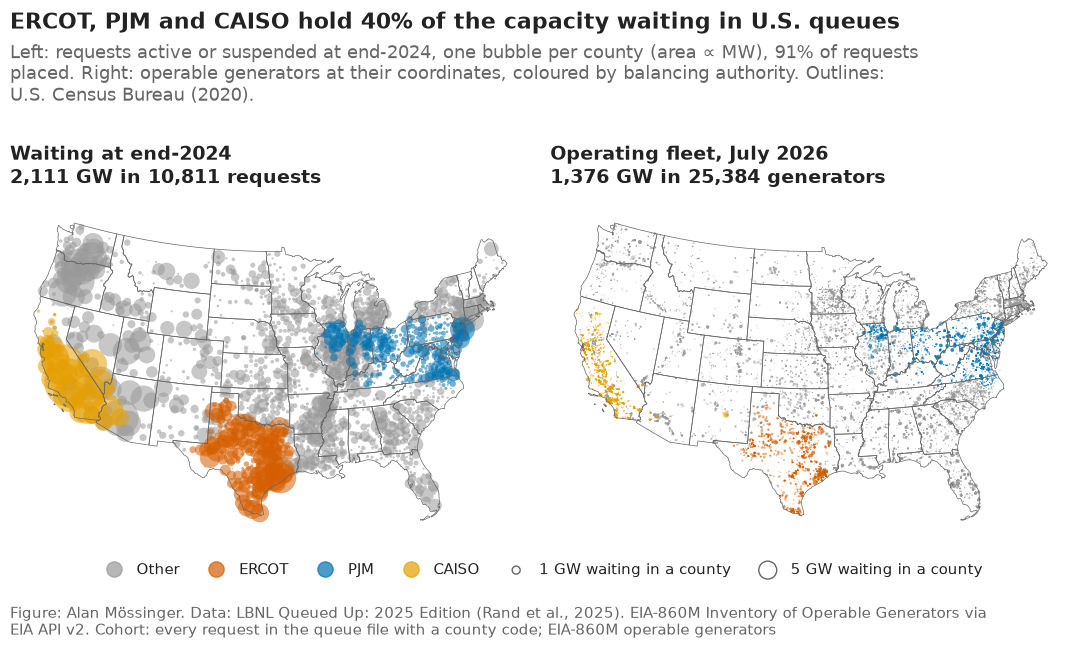

In [4]:
def draw_outline(ax):
    states.boundary.plot(ax=ax, color=MUTED, linewidth=0.5)
    ax.set_axis_off()
    ax.grid(False)


fig, (ax_q, ax_f) = plt.subplots(1, 2, figsize=(11, 6.5))
MW_PER_POINT = 30  # bubble area in points² = MW / 30, so area is proportional to capacity

draw_outline(ax_q)
for region in ["Other"] + TRACK_A:  # grey first so the ISO colours stay on top
    sub = by_county[by_county["region"].isin(TRACK_A) == (region != "Other")]
    sub = sub if region == "Other" else sub[sub["region"] == region]
    ax_q.scatter(sub.geometry.x, sub.geometry.y, s=sub["mw"] / MW_PER_POINT,
                 color=plots.region_color(region), alpha=0.55, linewidths=0, label=region)
ax_q.set_anchor("N")  # maps sit right under their titles; the free band below holds the legend
ax_q.set_title(f"Waiting at end-2024\n{waiting['mw'].sum() / 1e3:,.0f} GW in {len(waiting):,} requests")

draw_outline(ax_f)
for region in ["Other"] + TRACK_A:
    sub = fleet[fleet["region"] == region]
    ax_f.scatter(sub.geometry.x, sub.geometry.y, s=0.6 + sub["nameplate-capacity-mw"] / 120,
                 color=plots.region_color(region), alpha=0.45, linewidths=0, label=region)
ax_f.set_title(f"Operating fleet, July 2026\n{fleet['nameplate-capacity-mw'].sum() / 1e3:,.0f} GW "
               f"in {len(fleet):,} generators")
ax_f.set_anchor("N")

# legend handles with fixed sizes: a region's handle must not inherit the size of its first bubble
handles = [Line2D([], [], marker="o", linestyle="", markersize=11, color=plots.region_color(r), alpha=0.7, label=r)
           for r in ["Other"] + TRACK_A]
handles += [plt.scatter([], [], s=gw * 1e3 / MW_PER_POINT, facecolors="none", edgecolors=MUTED, linewidths=1,
                        label=f"{gw} GW waiting in a county") for gw in (1, 5)]

plots.finish(
    fig,
    f"ERCOT, PJM and CAISO hold {share_track_a:.0%} of the capacity waiting in U.S. queues",
    f"Left: requests active or suspended at end-2024, one bubble per county (area ∝ MW), "
    f"{points['matched'].mean():.0%} of requests placed. Right: operable generators at their coordinates, "
    f"coloured by balancing authority. Outlines: U.S. Census Bureau (2020).",
    cohort="every request in the queue file with a county code; EIA-860M operable generators",
    eia=True)
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.085), ncol=6, fontsize=11,
           columnspacing=1.4, handletextpad=0.5)
plots.save_fig(fig, "F9_project_map",
               "Requests waiting in U.S. interconnection queues at end-2024 by county (left) and the "
               "operating fleet from EIA-860M (right), with ERCOT, PJM and CAISO in their fixed colours.",
               "03b_project_map")
plt.show()

**Reading this.** The left panel is the portfolio manager's territory: 2,111 GW waiting in 10,811 placed requests, and 40% of that capacity in the three ISOs this project can time. Texas alone holds 19% of the waiting capacity (409 GW), California 250 GW; the next largest states are Oregon (127 GW), Arizona (106 GW) and Illinois (92 GW), all in regions where the public file gives no usable event dates, so a book there can be ranked by Track B but not timed. The right panel shows the fleet the queue would join: 1,376 GW in 25,384 generators, dense in the east and along the coasts and thin in the mountain west, where the queue's largest grey bubbles sit. The contrast between the two panels is the point: the queue is where the fleet is not. Two caveats: a bubble is a county total, not a site, and ERCOT is understated because a fifth of its requests carry no county code.

## 4. Share built, by state

A companion map for the portfolio reader: among requests that entered in 2010–2018 and have resolved (operational or withdrawn) by end-2024, the share that reached operation, by state. States with fewer than 30 resolved requests are hatched, because a share on so few requests is noise. This is the same quantity as the region × technology base rates of notebook 03, cut by state instead.

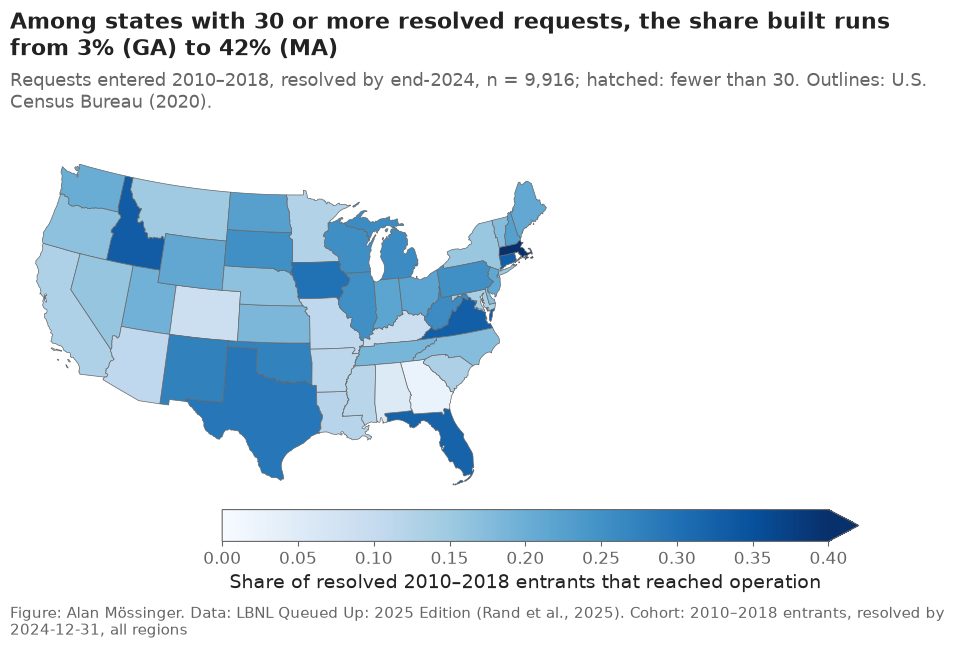

,resolved,operational,share_built,enough
state,,,,
MA,83,35,0.422,True
ID,196,65,0.332,True
CT,61,20,0.328,True
VA,382,125,0.327,True
FL,308,99,0.321,True
IA,110,33,0.300,True
TX,721,209,0.290,True
NM,160,44,0.275,True


In [5]:
resolved = points[points["q_year"].between(2010, 2018) & points["q_status"].isin(["operational", "withdrawn"])]
built = (resolved.groupby("state")
         .agg(resolved=("q_status", "size"), operational=("q_status", lambda s: int((s == "operational").sum())))
         .assign(share_built=lambda d: (d["operational"] / d["resolved"]).round(3)))
built["enough"] = built["resolved"] >= 30
built.to_csv(paths.RESULTS / "map_built_share_by_state.csv")

layer = states.merge(built, left_on="STUSPS", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(11, 6.5))
layer[layer["enough"] == True].plot(column="share_built", cmap="Blues", ax=ax, linewidth=0.5, edgecolor=MUTED,
                                    legend=True, vmin=0, vmax=0.4,
                                    legend_kwds={"label": "Share of resolved 2010–2018 entrants that reached operation",
                                                 "orientation": "horizontal", "shrink": 0.6, "pad": 0.02})
layer[layer["enough"] != True].plot(ax=ax, facecolor="white", edgecolor=MUTED, linewidth=0.5, hatch="///")
ax.set_axis_off(); ax.grid(False)
ax.set_anchor("W")  # map at the left edge, so the title aligns with it and the subtitle has the full width

top = built[built["enough"]].sort_values("share_built", ascending=False)
plots.finish(
    fig,
    f"Among states with 30 or more resolved requests, the share built runs from "
    f"{top['share_built'].iloc[-1]:.0%} ({top.index[-1]}) to {top['share_built'].iloc[0]:.0%} ({top.index[0]})",
    f"Requests entered 2010–2018, resolved by end-2024, n = {int(built['resolved'].sum()):,}; "
    f"hatched: fewer than 30. Outlines: U.S. Census Bureau (2020).",
    cohort="2010–2018 entrants, resolved by 2024-12-31, all regions")
plots.save_fig(fig, "03b_02_built_share_by_state",
               "Share of resolved 2010–2018 entrants that reached operation, by state; states with fewer "
               "than 30 resolved requests hatched.",
               "03b_project_map", folder="03b_project_map")
plt.show()
top.head(8)

**Reading this.** Among the states with 30 or more resolved 2010–2018 entrants, the share that reached operation runs from 3% in Georgia and 5% in Alabama to 42% in Massachusetts (on 83 requests), 33% in Idaho and Virginia and 32% in Florida. The three timing ISOs sit apart: Texas 29% of 721, Pennsylvania 25% of 436, Illinois 25% and Ohio 22%, California 13% of 941. This is the state-level version of the region × technology base rates of notebook 03 and it is what the fair baseline of notebook 11 will have to beat; the map also shows why state carries so much of the regional signal in the LightGBM explanation of notebook 09. Colour reads by itself; the hatched states have too few resolved requests for their share to mean anything.

## 5. State archetypes: what kinds of market the queue contains (F25)

A company choosing where to look does not start from 48 states one by one. This section lets the data group them, without being told the outcome, on seven market features that exist in the files: the waiting queue relative to the operating fleet (GW waiting at end-2024 over EIA-860M nameplate), the shares of the waiting MW that are solar, storage (batteries and solar-plus-storage) and gas, the median size of a waiting request, the share of the waiting MW that entered in 2022–2024 (how hot the queue is) and the share of resolved 2010–2018 entrants that reached operation (the history). Features are standardised, reduced with principal components for the picture, and clustered with k-means; k is chosen by silhouette over 3–6 on the 48 states with 30 or more resolved entrants and then the clusters are tested on something they never saw: the share of 2017–2019 entrants that were operating by the end of 2024. An archetype that does not separate that outcome is a description; one that does is a screen.

In [6]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from src import drivers

q = queue[queue["state"].notna()].copy()
q["tech"] = q["type_clean"].map(plots.tech_group)
wait = q[q["q_status"].isin(["active", "suspended"])]
fleet_mw = eia[eia["status"] == "OP"].groupby("stateid")["nameplate-capacity-mw"].sum()
feat = pd.DataFrame({
    "queue_over_fleet": wait.groupby("state")["mw"].sum() / fleet_mw.reindex(wait.groupby("state")["mw"].sum().index),
    "solar_share": wait[wait["tech"] == "Solar"].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "storage_share": wait[wait["tech"].isin(["Battery", "Solar+Battery"])].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "gas_share": wait[wait["tech"] == "Gas"].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "median_mw_waiting": wait.groupby("state")["mw"].median(),
    "recent_entry_share": wait[wait["q_year"] >= 2022].groupby("state")["mw"].sum() / wait.groupby("state")["mw"].sum(),
    "share_built_2010_2018": built["share_built"],
}).fillna(0.0)
feat = feat.loc[built.index[built["enough"]]].replace([np.inf, -np.inf], np.nan).dropna()
later = q[q["q_year"].between(2017, 2019)]
outcome = later.groupby("state").agg(n_2017_2019=("q_status", "size"), operating=("q_status", lambda s: int((s == "operational").sum())))
Z = StandardScaler().fit_transform(feat)
sil = {k: silhouette_score(Z, KMeans(n_clusters=k, n_init=20, random_state=3).fit_predict(Z)) for k in range(3, 7)}
K_BEST = max(sil, key=sil.get)
km = KMeans(n_clusters=K_BEST, n_init=20, random_state=3).fit(Z)
pca = PCA(n_components=2, random_state=3).fit(Z)
coords = pca.transform(Z)
arch = feat.assign(archetype=km.labels_, pc1=coords[:, 0], pc2=coords[:, 1]).join(outcome)
profile = arch.groupby("archetype").agg(states=("pc1", "size"), **{c: (c, "median") for c in feat.columns},
                                        n_2017_2019=("n_2017_2019", "sum"), operating=("operating", "sum"))
profile["completion_2017_2019"] = profile["operating"] / profile["n_2017_2019"]
profile["low"], profile["high"] = drivers.wilson(profile["operating"], profile["n_2017_2019"])
profile = profile.sort_values("completion_2017_2019", ascending=False)
NAMES = {}
for a, r in profile.iterrows():
    hot = "hot" if r["recent_entry_share"] >= profile["recent_entry_share"].median() else "settled"
    mix = "storage-heavy" if r["storage_share"] >= 0.35 else ("solar-heavy" if r["solar_share"] >= 0.45 else ("gas-leaning" if r["gas_share"] >= 0.15 else "mixed"))
    load = "crowded" if r["queue_over_fleet"] >= profile["queue_over_fleet"].median() else "light"
    NAMES[a] = f"{load} queue, {mix}, {hot}"
profile["name"] = pd.Series(NAMES)
arch["name"] = arch["archetype"].map(NAMES)
arch["state_list"] = ""
arch.round(4).to_csv(paths.RESULTS / "state_archetypes.csv")
profile.assign(state_list=arch.groupby("archetype")["name"].apply(lambda s: ", ".join(sorted(s.index)))).round(3).to_csv(paths.RESULTS / "archetype_profiles.csv")
sep = profile["completion_2017_2019"].max() - profile["completion_2017_2019"].min()
print(f"{len(feat)} states; silhouette by k: { {k: round(v, 3) for k, v in sil.items()} } → k = {K_BEST}; explained variance of two components {pca.explained_variance_ratio_.sum():.0%}")
print(f"2017–2019 completion by end-2024 runs from {profile['completion_2017_2019'].min():.1%} to {profile['completion_2017_2019'].max():.1%} across archetypes (spread {sep:.1%})")
for a, r in profile.iterrows():
    print(f"  A{a + 1} {r['name']}: {', '.join(sorted(arch.index[arch['archetype'] == a]))}")
profile[["name", "states"] + list(feat.columns) + ["n_2017_2019", "completion_2017_2019", "low", "high"]].round(3)

47 states; silhouette by k: {3: 0.202, 4: 0.203, 5: 0.202, 6: 0.203} → k = 4; explained variance of two components 52%
2017–2019 completion by end-2024 runs from 5.5% to 19.7% across archetypes (spread 14.2%)
  A1 light queue, mixed, settled: DE, FL, MD, MT, OH, PA, VA, WV
  A4 crowded queue, storage-heavy, hot: CT, IA, ID, IL, IN, MA, ME, MI, ND, NH, NJ, NM, NY, OK, SD, TX, VT, WA, WI, WY
  A3 crowded queue, storage-heavy, settled: AZ, CA, NV, OR, UT
  A2 light queue, gas-leaning, hot: AL, AR, CO, GA, KS, KY, LA, MN, MO, MS, NC, NE, SC, TN


,name,states,queue_over_fleet,solar_share,storage_share,gas_share,median_mw_waiting,recent_entry_share,share_built_2010_2018,n_2017_2019,completion_2017_2019,low,high
archetype,,,,,,,,,,,,,
0,"light queue, mixed, settled",8,0.794,0.379,0.300,0.034,55.250,0.305,0.236,1358,0.197,0.177,0.219
3,"crowded queue, storage-heavy, hot",20,1.430,0.234,0.378,0.026,150.000,0.678,0.252,2565,0.115,0.103,0.128
2,"crowded queue, storage-heavy, settled",5,3.500,0.047,0.795,0.030,254.855,0.542,0.159,895,0.070,0.055,0.089
1,"light queue, gas-leaning, hot",14,1.212,0.423,0.262,0.160,151.750,0.674,0.119,1287,0.055,0.044,0.069


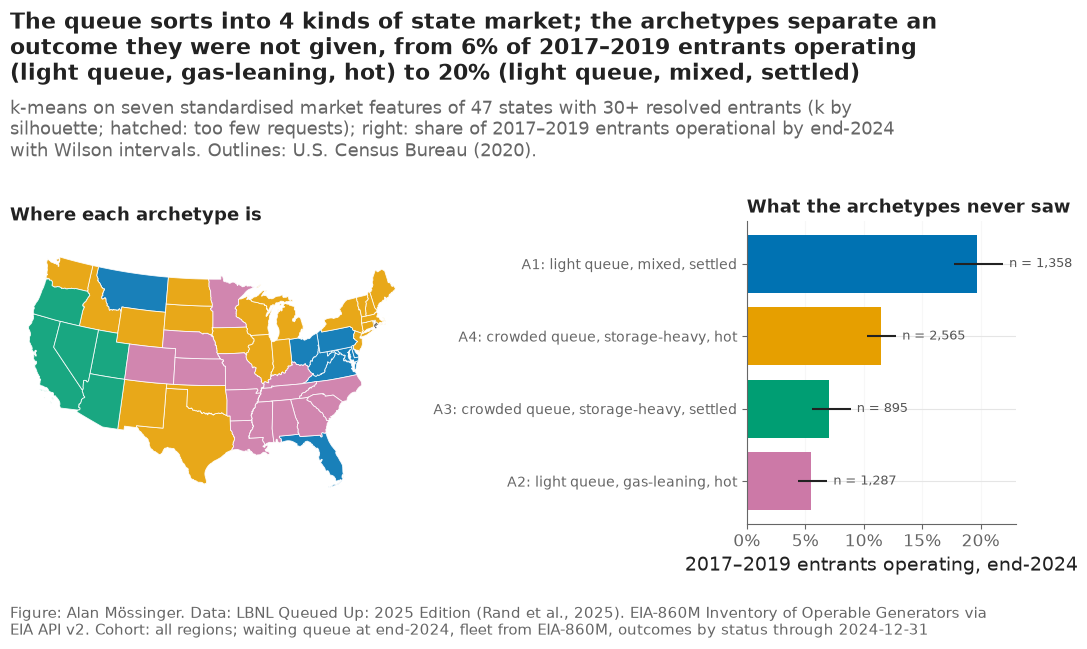

In [7]:
ARCH_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
colour_of = {a: ARCH_COLORS[i] for i, a in enumerate(profile.index)}
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
layer = states.merge(arch[["archetype"]], left_on="STUSPS", right_index=True, how="left")
layer[layer["archetype"].isna()].plot(ax=ax, facecolor="white", edgecolor=MUTED, linewidth=0.5, hatch="///")
for a in profile.index:
    part = layer[layer["archetype"] == a]
    if len(part):
        part.plot(ax=ax, facecolor=colour_of[a], edgecolor="white", linewidth=0.6, alpha=0.9)
ax.set_axis_off(); ax.grid(False)
ax.set_title("Where each archetype is", fontsize=13, loc="left")
ax = axes[1]
y = np.arange(len(profile))
ax.barh(y, profile["completion_2017_2019"], color=[colour_of[a] for a in profile.index])
ax.hlines(y, profile["low"], profile["high"], color=plots.INK, lw=1.5)
for yy, (a, r) in zip(y, profile.iterrows()):
    ax.text(r["high"] + 0.005, yy, f"n = {int(r['n_2017_2019']):,}", va="center", fontsize=9.5, color="#555555")
ax.set_yticks(y)
ax.set_yticklabels([f"A{a + 1}: {r['name']}" for a, r in profile.iterrows()], fontsize=10)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("2017–2019 entrants operating, end-2024")
ax.set_title("What the archetypes never saw", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
best, worst = profile.iloc[0], profile.iloc[-1]
plots.finish(fig,
             f"The queue sorts into {K_BEST} kinds of state market; the archetypes separate an outcome they were not given, "
             f"from {worst['completion_2017_2019']:.0%} of 2017–2019 entrants operating ({worst['name']}) to {best['completion_2017_2019']:.0%} ({best['name']})",
             f"k-means on seven standardised market features of {len(feat)} states with 30+ resolved entrants (k by silhouette; hatched: too few requests); "
             f"right: share of 2017–2019 entrants operational by end-2024 with Wilson intervals. Outlines: U.S. Census Bureau (2020).",
             cohort="all regions; waiting queue at end-2024, fleet from EIA-860M, outcomes by status through 2024-12-31", eia=True)
plots.save_fig(fig, "F25_state_archetypes", "State archetypes from k-means on seven market features (queue relative to the fleet, technology mix of the waiting MW, median request size, recent-entry share, historical share built), mapped, and the share of 2017–2019 entrants operating by end-2024 in each archetype with Wilson intervals.", "03b_project_map")
plt.show()

**Reading this.** Four kinds of state market come out of seven features, and the structure is soft (silhouette about 0.20 for every k from 3 to 6, so k is a choice more than a discovery), but the archetypes separate an outcome they were never given: the share of 2017–2019 entrants operating by the end of 2024 runs from 5.5% to 19.7% across them.

- **A1, a light, settled queue with a mixed technology list** (DE, FL, MD, MT, OH, PA, VA, WV: the PJM core and Florida): queue below the fleet (0.8×), 31% of the waiting MW entered since 2022, a history of 24% built, and 19.7% of 2017–2019 entrants operating. This is where entry odds are best.
- **A4, a crowded, hot, storage-heavy queue** (20 states from New England and the upper Midwest to Texas and the mountain west): queue 1.4× the fleet, two thirds of it entered since 2022, 11.5% of 2017–2019 entrants operating. Texas sits here: its base rate is high but its queue has doubled.
- **A3, the crowded, settled, storage-dominated Southwest** (AZ, CA, NV, OR, UT): queue 3.5× the fleet, 80% of the waiting MW is storage or hybrids, 7.0% operating. Entry odds are a third of A1's, and the plants waiting are the ones with negative merchant NPV in notebook 15.
- **A2, a light, hot, gas-leaning queue** (AL, AR, CO, GA, KS, KY, LA, MN, MO, MS, NC, NE, SC, TN: the Southeast and plains): 16% gas in the waiting MW, a history of 12% built and 5.5% operating. Most of these states are outside the three timing ISOs, so the public file dates few of their outcomes.

For a company the map is a first screen, not a ranking of states: look in A1 for entry, in A4 only where the agreement can be dated (Texas), treat A3 as a market that needs a contract, and A2 as one the public data cannot yet time.

## 6. Checks

In [8]:
checks = pd.DataFrame([
    {"check": "state totals on the map equal the clean file",
     "value": int(by_state.filter(like="n_").sum().sum()), "expected": int(points["state"].notna().sum()),
     "pass": int(by_state.filter(like="n_").sum().sum()) == int(points["state"].notna().sum())},
    {"check": "requests without a county position ≤ 10%",
     "value": round(float((~points["matched"]).mean()), 3), "expected": "≤ 0.10",
     "pass": bool((~points["matched"]).mean() <= 0.10)},
    {"check": "archetypes separate the 2017–2019 outcome (spread ≥ 5 points) and F25 saved",
     "value": round(float(sep), 3), "expected": "≥ 0.05",
     "pass": bool(sep >= 0.05) and (paths.FIGURES / "F25_state_archetypes.png").exists()},
    {"check": "F9 saved as PNG and SVG",
     "value": int((paths.FIGURES / "F9_project_map.png").exists()) + int((paths.FIGURES / "F9_project_map.svg").exists()),
     "expected": 2,
     "pass": (paths.FIGURES / "F9_project_map.png").exists() and (paths.FIGURES / "F9_project_map.svg").exists()},
])
checks.to_csv(paths.RESULTS / "map_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,expected,pass
0,state totals on the map equal the clean file,36155.000,36155,True
1,requests without a county position ≤ 10%,0.086,≤ 0.10,True
2,archetypes separate the 2017–2019 outcome (spr...,0.142,≥ 0.05,True
3,F9 saved as PNG and SVG,2.000,2,True


## Takeaways

- 91.4% of the 36,216 requests in the clean file can be placed by county; the gap is in MISO (35% without a code) and ERCOT (21%).
- At end-2024, 2,111 GW were waiting in 10,811 placed requests; ERCOT, PJM and CAISO hold 40% of that capacity, Texas alone 19%.
- The waiting queue is densest where the operating fleet (1,376 GW, 25,384 generators) is thinnest: the mountain west and the southern plains.
- The share of resolved 2010–2018 entrants that reached operation runs from 3% (Georgia) to 42% (Massachusetts) across states with 30 or more; Texas 29%, Pennsylvania 25%, California 13%.
- **State archetypes (section 5, F25):** k-means on seven market features sorts 47 states into four kinds of market; the archetypes separate the share of 2017–2019 entrants operating by end-2024 (5.5% in the hot gas-leaning Southeast and plains, 7.0% in the storage-dominated Southwest, 11.5% in the crowded hot queues that include Texas, 19.7% in the light settled queues of the PJM core and Florida).
- **What goes to the report:** F25 as the opening of the "where is the opportunity" section; F9 in the data section as the geography of the decision; the state map as a companion to the base rates; `results/map_unmatched.csv` for the limitations.